# 01 – Data and feature engineering (BTC, ETH, BNB, XRP, ADA, SOL – 8 h candles)

**Goal:** download the 8-hour candles (3 per day), check their quality, build the features, split train / test and save everything the HMM notebooks need.

**Run the notebook from top to bottom.** Each code cell has a short description above it.

| Step | Cells | Output |
|---|---|---|
| 1. Setup | 1–2 | libraries, parameters, check of `src/fonctions.py` |
| 2. Download | 3–5 | `data/<crypto>_8h.csv` (and BTC 1 h, optional) |
| 3. Quality checks | 6–7 | summary table, list of missing bars |
| 4. Features | 8–11 | features, ADF test, correlations |
| 5. Split, scale, save | 12–15 | `data/<crypto>_features.csv`, `_X_train.csv`, `_X_test.csv`, `_scaler.joblib` |
| 6. Final check | 16 | automatic verification of the saved files |

**Requires:** `src/fonctions.py` (with `charger_binance`, the `calculer_*` functions and `construire_features`).

## 1. Setup

### Cell 1 – Libraries and parameters
Imports the libraries and defines **all the parameters in one place**: cryptos, dates, windows of the indicators, feature set, train/test proportion. To change a choice, change it here only.

Windows are the daily ones multiplied by 3 (3 candles per day): volatility 20 days → 60, RSI 14 days → 42, MACD 12/26/9 → 36/78/27.

In [1]:
import sys, os, warnings
sys.path.append("../src")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns, joblib
from statsmodels.tsa.stattools import adfuller
from sklearn.preprocessing import StandardScaler
from fonctions import *

warnings.filterwarnings("ignore", category=FutureWarning)

# --- data
CRYPTOS = ["BTCUSDT", "ETHUSDT", "BNBUSDT", "XRPUSDT", "ADAUSDT", "SOLUSDT"]
DEBUT, FIN = "2017-08-17", "2026-11-01"
TELECHARGER    = True    # True = download again ; False = reuse the CSV files already in data/
TELECHARGER_1H = False   # True = also download BTC 1 h (about 77,000 rows, only for the LSTM bonus)

# --- indicator windows (8 h candles)
PAR_JOUR = 3
FEN_VOL, FEN_RSI, MACD = 60, 42, (36, 78, 27)

# --- feature sets and split
JEUX = {"base":   ["rendement", "volatilite"],                      # baseline
        "etendu": ["rendement", "volatilite", "RSI", "vol_rel"]}    # extended set
JEU = "base"                                                        # choose "base" or "etendu"
CHOIX = JEUX[JEU]
TRAIN_FRAC = 0.7                                                    # chronological split, no shuffling

for dossier in ("../data", "../results"):
    os.makedirs(dossier, exist_ok=True)
print("Feature set used:", JEU, CHOIX)

Feature set used: base ['rendement', 'volatilite']


### Cell 2 – Check that `src/fonctions.py` is up to date
Stops with a **clear message** if a function is missing (typical cause: an old `fonctions.py`, or a kernel that was not restarted after editing it).

In [3]:
requises = ["charger_binance", "calculer_rendement_log", "calculer_volatilite",
            "calculer_RSI", "calculer_MACD", "construire_features"]
manquantes = [f for f in requises if f not in globals()]
assert not manquantes, (f"Missing in src/fonctions.py: {manquantes}. "
                        "Replace src/fonctions.py with the provided file, then Kernel > Restart.")
print("fonctions.py OK")

fonctions.py OK


## 2. Download

### Cell 3 – Download the 8 h candles (6 cryptos)
Downloads from the Binance public API (1000 candles per request, with pagination) and saves `data/<crypto>_8h.csv`. With `TELECHARGER = False`, existing files are reused (fast re-runs). Prices are in USDT. Each crypto starts at its own listing date.

In [5]:
for nom in CRYPTOS:
    chemin = f"../data/{nom.lower()}_8h.csv"
    if TELECHARGER or not os.path.exists(chemin):
        d = charger_binance(nom, "8h", DEBUT, FIN)
        d.to_csv(chemin)
        etat = "downloaded"
    else:
        d = pd.read_csv(chemin, index_col=0, parse_dates=True)
        etat = "reused"
    print(f"{nom:8s} {etat:10s} {str(d.shape):12s} start: {d.index[0]}")

BTCUSDT  downloaded (10087, 5)   start: 2017-08-17 00:00:00
ETHUSDT  downloaded (10087, 5)   start: 2017-08-17 00:00:00
BNBUSDT  downloaded (9844, 5)    start: 2017-11-06 00:00:00
XRPUSDT  downloaded (9309, 5)    start: 2018-05-04 08:00:00
ADAUSDT  downloaded (9361, 5)    start: 2018-04-17 00:00:00
SOLUSDT  downloaded (6820, 5)    start: 2020-08-11 00:00:00


### Cell 4 – BTC 1 h (optional, bonus for the LSTM)
Only runs if `TELECHARGER_1H = True`. 1 h candles are **never mixed** with the 8 h ones: one model = one frequency.

In [7]:
if TELECHARGER_1H:
    btc1h = charger_binance("BTCUSDT", "1h", "2018-01-01", FIN)
    btc1h.to_csv("../data/btcusdt_1h.csv")
    print("BTC 1h:", btc1h.shape)
else:
    print("BTC 1h skipped (TELECHARGER_1H = False)")

BTC 1h skipped (TELECHARGER_1H = False)


### Cell 5 – Detect old files from earlier tests
`btc_8h.csv` and `eth_8h.csv` come from an earlier download (9,676 rows from 2018, other source). The notebooks use `btcusdt_8h.csv` and `ethusdt_8h.csv`. This cell **lists** the old files so nobody mixes them up. Set `SUPPRIMER_ANCIENS = True` to delete them.

In [9]:
SUPPRIMER_ANCIENS = False
anciens = [f for f in ["../data/btc_8h.csv", "../data/eth_8h.csv"] if os.path.exists(f)]
if anciens and SUPPRIMER_ANCIENS:
    for f in anciens: os.remove(f)
    print("Deleted:", anciens)
else:
    print("Old files found:", anciens if anciens else "none")

Old files found: none


## 3. Quality checks

### Cell 6 – Summary table of the 6 datasets
For each crypto: number of rows, start and end dates, duplicates, missing values, zero volumes, and **gaps** (a gap = a time step larger than the usual 8 h; `missing bars` = how many candles are absent).

In [11]:
lignes = []
for nom in CRYPTOS:
    d = pd.read_csv(f"../data/{nom.lower()}_8h.csv", index_col=0, parse_dates=True).sort_index()
    pas = d.index.to_series().diff().dropna()
    normal = pas.mode()[0]
    trous = pas[pas > normal]
    lignes.append({"crypto": nom, "rows": len(d), "start": d.index[0].date(), "end": d.index[-1].date(),
                   "duplicates": int(d.index.duplicated().sum()), "NaN": int(d.isna().sum().sum()),
                   "zero volume": int((d["Volume"] == 0).sum()), "gaps": len(trous),
                   "missing bars": int((trous / normal - 1).round().sum())})
resume_qualite = pd.DataFrame(lignes).set_index("crypto")
resume_qualite

,rows,start,end,duplicates,NaN,zero volume,gaps,missing bars
crypto,,,,,,,,
BTCUSDT,10087,2017-08-17,2026-11-01,0,0,0,1,3
ETHUSDT,10087,2017-08-17,2026-11-01,0,0,0,1,3
BNBUSDT,9844,2017-11-06,2026-11-01,0,0,0,1,3
XRPUSDT,9309,2018-05-04,2026-11-01,0,0,0,0,0
ADAUSDT,9361,2018-04-17,2026-11-01,0,0,0,0,0
SOLUSDT,6820,2020-08-11,2026-11-01,0,0,0,0,0


### Cell 7 – Where are the missing bars? (BTC)
Lists each gap in BTC with the date and the number of missing candles. A few missing bars are negligible, so we **do not fill them**; mention them in the "data quality" paragraph of the report.

In [13]:
df = pd.read_csv("../data/btcusdt_8h.csv", index_col=0, parse_dates=True).sort_index()
df = df[~df.index.duplicated(keep="first")]

pas = df.index.to_series().diff()
normal = pas.dropna().mode()[0]
trous = pas[pas > normal]
pd.DataFrame({"bar after the gap": trous.index, "gap": trous.values,
              "missing bars": (trous / normal - 1).round().astype(int).values}).head(20)

,bar after the gap,gap,missing bars
0,2018-02-09 08:00:00,1 days 08:00:00,3


## 4. Features

### Cell 8 – Session effect on the volume (justifies `vol_rel`)
The 00:00, 08:00 and 16:00 candles do not have the same volume (the 08:00 bar is the busiest). A plain volume change therefore mostly measures *which bar of the day it is*. `vol_rel` compares each bar with the average volume of **the same session over the last 20 days** (past only).

Reading: the first column shows a clear session effect; the second column should be **close to equal** across sessions.

In [15]:
h = df.index.hour
dv = np.log1p(df["Volume"]).diff()
v_session = df["Volume"].groupby(h).transform(lambda s: s.rolling(20).mean().shift(1))
vol_rel = np.log(df["Volume"] / v_session).replace([np.inf, -np.inf], np.nan)

pd.DataFrame({"mean log-volume change (old var_volume)": dv.groupby(h).mean(),
              "mean vol_rel (used)": vol_rel.groupby(h).mean()}).round(2)

,mean log-volume change (old var_volume),mean vol_rel (used)
Date,,
0,-0.12,-0.11
8,0.30,-0.10
16,-0.18,-0.11


### Cell 9 – Compute the features (BTC)
Calls `construire_features` from `src/fonctions.py` (the same function is used for all cryptos and, later, by the dashboard). Features: `rendement` (log-return), `volatilite` (rolling std, 60 bars), `RSI` (42), `MACD_norm` and `histo_norm` (MACD / price), `amplitude` ((High−Low)/Close), `vol_rel`. The first rows have `NaN` because of the rolling windows: they are removed.

In [17]:
feat = construire_features(df, FEN_VOL, FEN_RSI, MACD)
print("NaN created by the windows:")
print(feat.isna().sum().to_string())
feat = feat.dropna()
print("\nRows kept:", len(feat), "of", len(df))
feat.describe().T.round(4)

NaN created by the windows:
rendement      1
volatilite    60
RSI           42
MACD_norm      0
histo_norm     0
amplitude      0
vol_rel       60

Rows kept: 10027 of 10087


,count,mean,std,min,25%,50%,75%,max
rendement,10027.0,0.0003,0.0200,-0.2449,-0.0070,0.0004,0.0078,0.1961
volatilite,10027.0,0.0178,0.0090,0.0041,0.0118,0.0158,0.0210,0.0576
RSI,10027.0,51.4582,8.6682,20.1020,45.8355,50.5266,56.9756,81.3347
MACD_norm,10027.0,0.0012,0.0428,-0.2187,-0.0192,0.0019,0.0271,0.1439
histo_norm,10027.0,0.0001,0.0129,-0.0875,-0.0064,0.0004,0.0078,0.0462
amplitude,10027.0,0.0276,0.0238,0.0015,0.0134,0.0211,0.0336,0.3792
vol_rel,10027.0,-0.1072,0.5415,-2.6287,-0.4222,-0.1115,0.2141,2.4597


### Cell 10 – Stationarity test (ADF)
Augmented Dickey-Fuller test on each feature. **p < 0.05 → stationary** (no unit root), which is why we model returns and not raw prices. Note: ADF does not say that the *variance* is constant; volatility clustering remains, and it is exactly what the HMM captures.

In [19]:
res = []
for c in feat.columns:
    p = adfuller(feat[c], autolag="AIC")[1]
    res.append({"variable": c, "p_value": p, "stationary (p<0.05)": p < 0.05})
pd.DataFrame(res).style.format({"p_value": "{:.2e}"})

,variable,p_value,stationary (p<0.05)
0,rendement,0.00e+00,True
1,volatilite,1.98e-07,True
2,RSI,1.26e-13,True
3,MACD_norm,2.38e-12,True
4,histo_norm,9.74e-28,True
5,amplitude,3.04e-12,True
6,vol_rel,2.04e-27,True


### Cell 11 – Correlation between features
Heatmap + list of pairs with |correlation| > 0.7. Two features that are almost copies of each other make a full-covariance HMM unstable, so we keep **one** of each such pair. Saved to `results/correlation_features.png`.

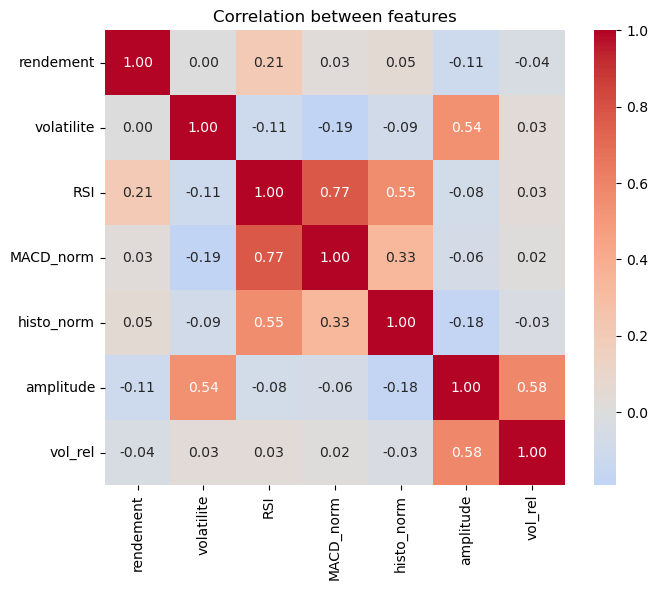

Pairs with |corr| > 0.7: [('RSI', 'MACD_norm', 0.77)]


In [21]:
corr = feat.corr()
plt.figure(figsize=(7, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation between features")
plt.tight_layout()
plt.savefig("../results/correlation_features.png", dpi=150)
plt.show()

forts = [(a, b, round(corr.loc[a, b], 2)) for i, a in enumerate(corr.columns)
         for b in corr.columns[i+1:] if abs(corr.loc[a, b]) > 0.7]
print("Pairs with |corr| > 0.7:", forts)

## 5. Split, scale and save

### Cell 12 – Function `preparer` (features → split → scaling)
For one crypto: builds the features, keeps the columns of the chosen set (`CHOIX`), splits **chronologically** (first 70 % train, last 30 % test) and standardizes with a `StandardScaler` **fitted on the train only** (no look-ahead). With `sauvegarder=True` it writes the 4 files used by the next notebooks.

In [23]:
def preparer(nom, sauvegarder=False):
    d = pd.read_csv(f"../data/{nom.lower()}_8h.csv", index_col=0, parse_dates=True).sort_index()
    d = d[~d.index.duplicated(keep="first")]
    f = construire_features(d, FEN_VOL, FEN_RSI, MACD).dropna()
    X = f[CHOIX]
    k = int(len(X) * TRAIN_FRAC)
    sc = StandardScaler().fit(X.iloc[:k])                       # fit on TRAIN only
    X_train = pd.DataFrame(sc.transform(X.iloc[:k]), index=X.index[:k], columns=CHOIX)
    X_test  = pd.DataFrame(sc.transform(X.iloc[k:]), index=X.index[k:], columns=CHOIX)
    if sauvegarder:
        n = nom.lower()
        f.join(d["Close"]).to_csv(f"../data/{n}_features.csv")
        X_train.to_csv(f"../data/{n}_X_train.csv")
        X_test.to_csv(f"../data/{n}_X_test.csv")
        joblib.dump(sc, f"../data/{n}_scaler.joblib")
    return f, X_train, X_test, sc
print("preparer defined")

preparer defined


### Cell 13 – Look at the BTC split
Shows the train and test periods and the mean of each scaled variable. The train mean is ≈ 0 by construction. A test mean **different from 0** is normal and informative: it says how much the test period differs from the training period (for example a calmer market).

In [25]:
feat_btc, X_train, X_test, scaler = preparer("BTCUSDT")
print("train:", X_train.index[0].date(), "->", X_train.index[-1].date(), len(X_train), "rows")
print("test :", X_test.index[0].date(),  "->", X_test.index[-1].date(),  len(X_test),  "rows")
pd.DataFrame({"train mean": X_train.mean(), "test mean": X_test.mean()}).round(2)

train: 2017-09-06 -> 2024-02-02 7018 rows
test : 2024-02-02 -> 2026-11-01 3009 rows


,train mean,test mean
rendement,0.0,-0.01
volatilite,-0.0,-0.70


### Cell 14 – Plot the features and the split (BTC)
Return, volatility and relative volume over time, with a vertical line where the test period starts. Saved to `results/features_btc.png` (useful for the report).

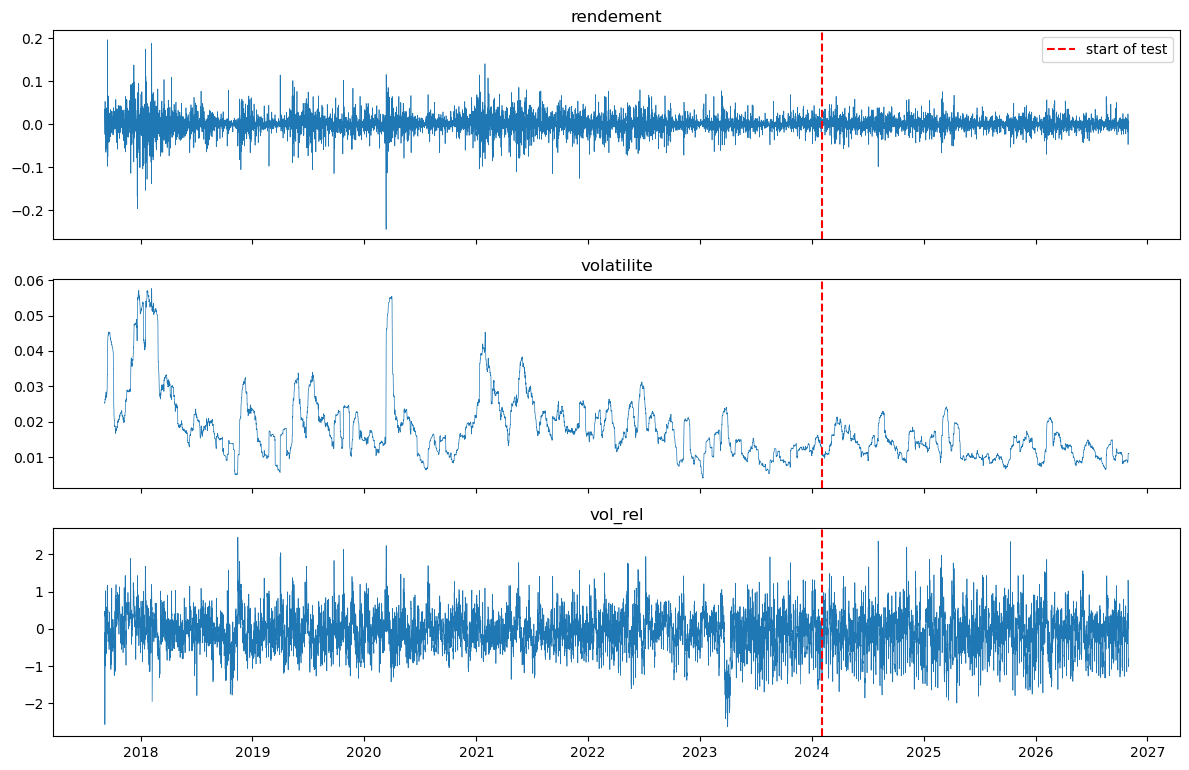

In [27]:
cols = [c for c in ["rendement", "volatilite", "vol_rel"] if c in feat_btc.columns]
fig, axes = plt.subplots(len(cols), 1, figsize=(12, 2.6 * len(cols)), sharex=True)
for ax, c in zip(np.atleast_1d(axes), cols):
    ax.plot(feat_btc.index, feat_btc[c], lw=0.5)
    ax.axvline(X_test.index[0], color="red", ls="--", label="start of test")
    ax.set_title(c)
np.atleast_1d(axes)[0].legend()
plt.tight_layout()
plt.savefig("../results/features_btc.png", dpi=150)
plt.show()

### Cell 15 – Process and save all 6 cryptos
Runs `preparer(..., sauvegarder=True)` for each crypto. For each one it writes `data/<crypto>_features.csv` (all features + `Close`), `_X_train.csv`, `_X_test.csv` and `_scaler.joblib` (to reuse the same scaling later, e.g. in the dashboard).

In [29]:
lignes = []
for nom in CRYPTOS:
    f, Xtr, Xte, sc = preparer(nom, sauvegarder=True)
    lignes.append({"crypto": nom, "rows": len(f), "train": len(Xtr), "test": len(Xte),
                   "train start": Xtr.index[0].date(), "test start": Xte.index[0].date(),
                   "end": Xte.index[-1].date()})
pd.DataFrame(lignes).set_index("crypto")

,rows,train,test,train start,test start,end
crypto,,,,,,
BTCUSDT,10027,7018,3009,2017-09-06,2024-02-02,2026-11-01
ETHUSDT,10027,7018,3009,2017-09-06,2024-02-02,2026-11-01
BNBUSDT,9784,6848,2936,2017-11-26,2024-02-26,2026-11-01
XRPUSDT,9249,6474,2775,2018-05-24,2024-04-20,2026-11-01
ADAUSDT,9301,6510,2791,2018-05-07,2024-04-15,2026-11-01
SOLUSDT,6760,4732,2028,2020-08-31,2024-12-25,2026-11-01


## 6. Final check

### Cell 16 – Automatic verification of the saved files
Reloads the saved BTC files and checks: no `NaN`, same columns as the chosen set and as the scaler, dates in increasing order, and **the test starts after the train ends**. Prints `ALL CHECKS PASSED` if everything is fine.

In [31]:
n = "btcusdt"
Xtr = pd.read_csv(f"../data/{n}_X_train.csv", index_col=0, parse_dates=True)
Xte = pd.read_csv(f"../data/{n}_X_test.csv",  index_col=0, parse_dates=True)
ft  = pd.read_csv(f"../data/{n}_features.csv", index_col=0, parse_dates=True)
sc  = joblib.load(f"../data/{n}_scaler.joblib")

assert not Xtr.isna().any().any() and not Xte.isna().any().any(), "NaN in X files"
assert list(Xtr.columns) == CHOIX == list(sc.feature_names_in_), "columns differ from the chosen set"
assert Xtr.index.is_monotonic_increasing and Xte.index.is_monotonic_increasing, "dates not sorted"
assert Xtr.index[-1] < Xte.index[0], "test must start after train"
assert set(CHOIX) <= set(ft.columns) and "Close" in ft.columns, "features file incomplete"
print("ALL CHECKS PASSED |", len(Xtr), "train rows,", len(Xte), "test rows | features:", CHOIX)

ALL CHECKS PASSED | 7018 train rows, 3009 test rows | features: ['rendement', 'volatilite']


## Next step
Notebook `04_hmm_rendements`: train the HMM on `data/btcusdt_X_train.csv` (N = 2 to 5, AIC/BIC, several initializations), interpret the regimes, then predict the next regime with the forward filter (no look-ahead).